In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path

# Do we think the same thing is happening in all of these countries?

This is a hypothetical dataset representing pesticide residues above a safety threshold vs. percentage of organic farms in different countries. How can we tell if trends are consistent across countries?

In [2]:
for file in Path('.').glob("*.csv"):
    df = pd.read_csv(file)
    x, y = df['x'], df['y']
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    coeff = np.polyfit(x, y, deg=1)
    corr = np.corrcoef(x, y)[0, 1]
    
    print(f"x_mean={x_mean:.3f}, y_mean={y_mean:.3f}, linear regression fr(x)={coeff[1]:.1f} {coeff[0]:.2f} x, r = {corr:.3f} ")

x_mean=54.261, y_mean=47.830, linear regression fr(x)=53.2 -0.10 x, r = -0.062 
x_mean=54.268, y_mean=47.836, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.269, y_mean=47.831, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.266, y_mean=47.831, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.267, y_mean=47.838, linear regression fr(x)=53.8 -0.11 x, r = -0.068 
x_mean=54.267, y_mean=47.840, linear regression fr(x)=53.3 -0.10 x, r = -0.063 
x_mean=54.263, y_mean=47.832, linear regression fr(x)=53.5 -0.10 x, r = -0.064 
x_mean=54.260, y_mean=47.840, linear regression fr(x)=53.6 -0.11 x, r = -0.066 
x_mean=54.260, y_mean=47.840, linear regression fr(x)=53.1 -0.10 x, r = -0.060 
x_mean=54.270, y_mean=47.837, linear regression fr(x)=53.9 -0.11 x, r = -0.069 
x_mean=54.269, y_mean=47.835, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.266, y_mean=47.835, linear regression fr(x)=53.4 -0.10 x, r = -0.064 
x_mean=54.267, y_mean=47.832, linear reg

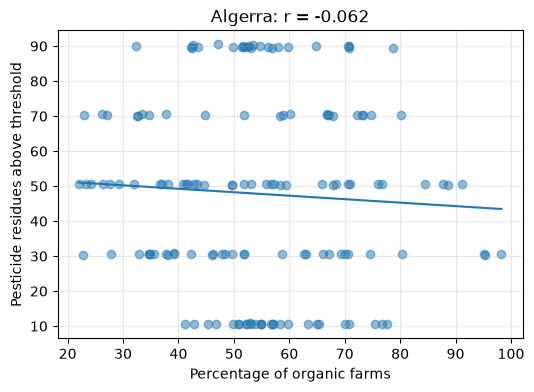

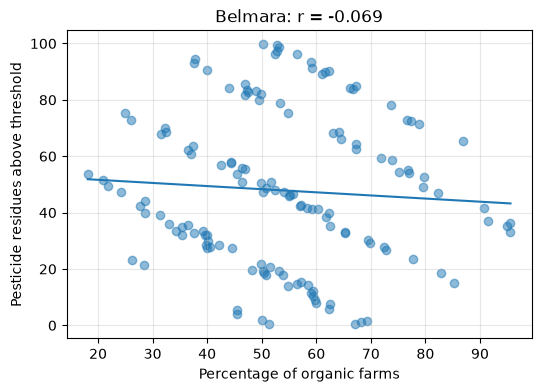

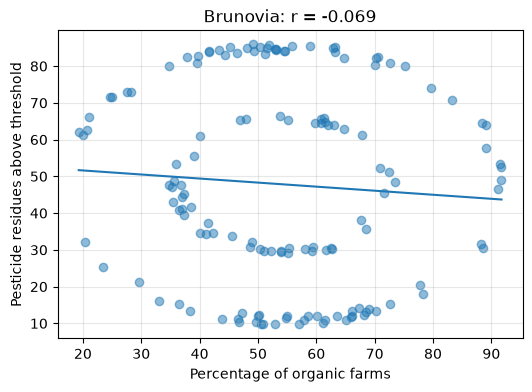

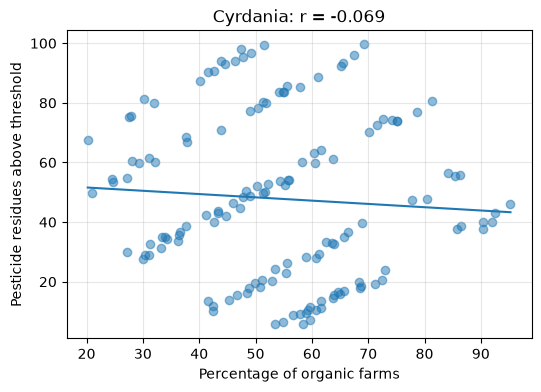

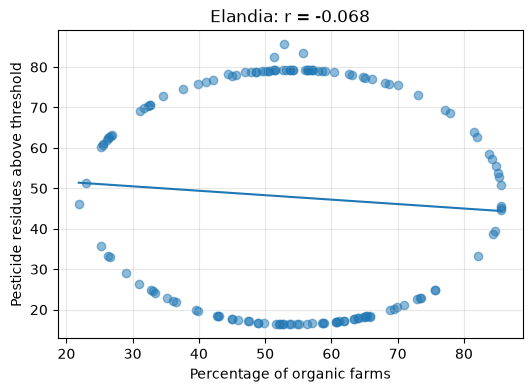

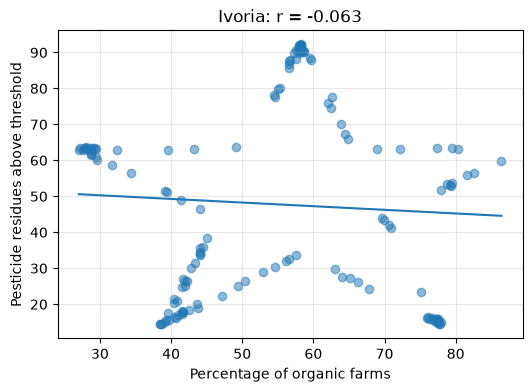

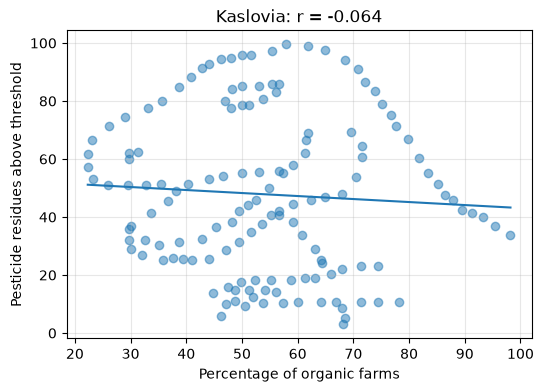

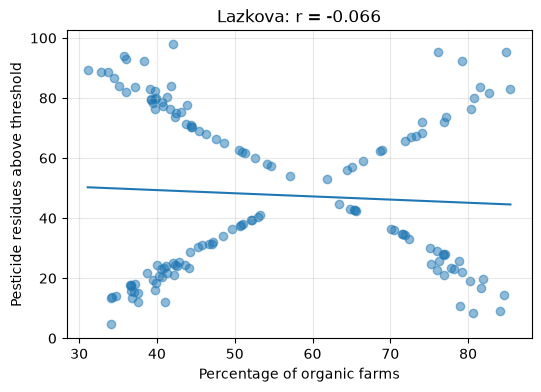

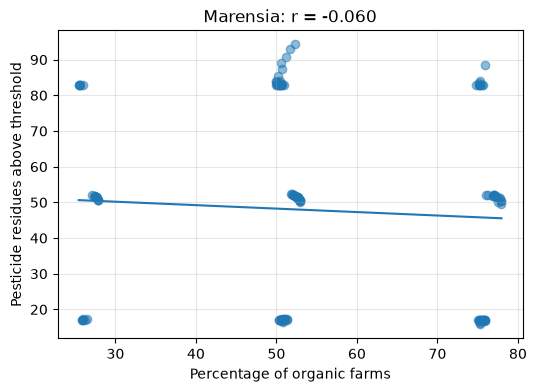

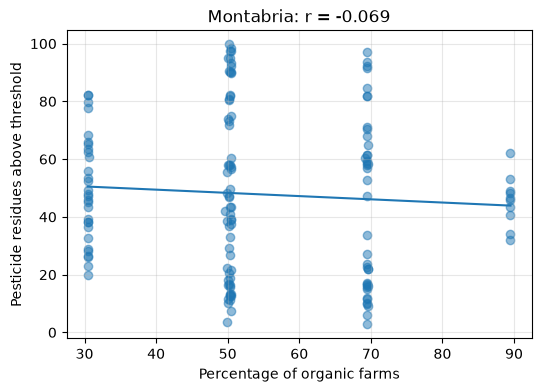

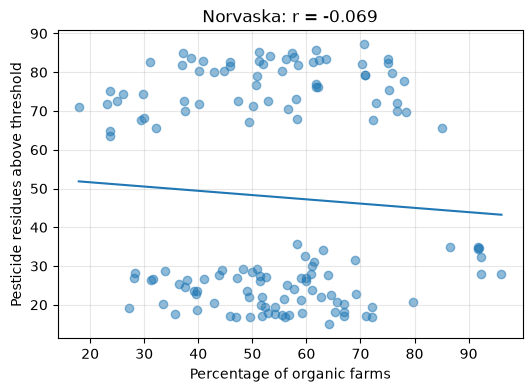

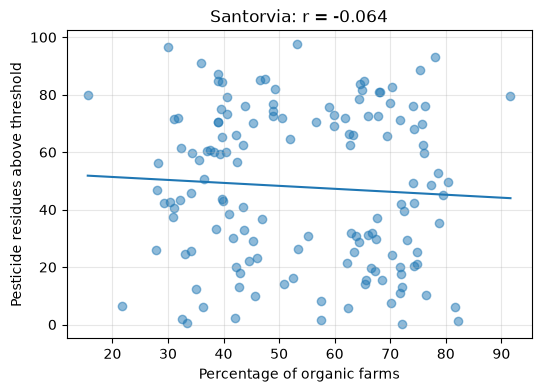

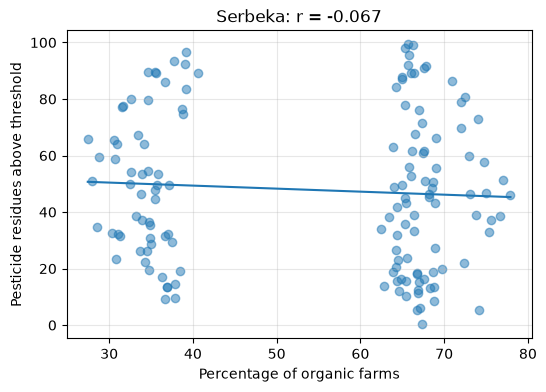

      Country  Slope  Intercept  Correlation
0     Algerra -0.099     53.211       -0.062
1     Belmara -0.111     53.850       -0.069
2    Brunovia -0.110     53.809       -0.069
3    Cyrdania -0.110     53.813       -0.069
4     Elandia -0.110     53.797       -0.068
5      Ivoria -0.101     53.327       -0.063
6    Kaslovia -0.104     53.453       -0.064
7     Lazkova -0.105     53.554       -0.066
8    Marensia -0.097     53.098       -0.060
9   Montabria -0.112     53.891       -0.069
10   Norvaska -0.110     53.809       -0.069
11  Santorvia -0.103     53.425       -0.064
12    Serbeka -0.107     53.635       -0.067


In [3]:
results = []

for file in sorted(Path(".").glob("*.csv")):
    df = pd.read_csv(file)

    x = df["x"]
    y = df["y"]

    # Linear regression
    slope, intercept = np.polyfit(x, y, 1)

    # Pearson correlation
    r = np.corrcoef(x, y)[0, 1]

    results.append({
        "Country": file.stem,
        "Slope": slope,
        "Intercept": intercept,
        "Correlation": r
    })

    # Scatterplot and regression line
    plt.figure(figsize=(6, 4))
    plt.scatter(x, y, alpha=0.5)

    x_line = np.linspace(x.min(), x.max(), 100)
    plt.plot(x_line, slope * x_line + intercept)

    plt.title(f"{file.stem}: r = {r:.3f}")
    plt.xlabel("Percentage of organic farms")
    plt.ylabel("Pesticide residues above threshold")
    plt.grid(alpha=0.3)
    plt.show()

# Comparison table
results_df = pd.DataFrame(results)
print(results_df.round(3))